# Construcción de un índice compuesto: condiciones socioeconómicas por entidad

Cuaderno del **Capítulo 4** de las notas. Usa los indicadores construidos en el cuaderno del Capítulo 3 (`03 Factor Analysis/04 Entidades ENIGH/enigh2024_entidades.csv`) y sigue los pasos del manual OCDE/JRC (2008).

**Contenido**
1. Selección de indicadores y polaridad
2. Normalización
3. Ponderación e importancia efectiva
4. Agregación lineal y geométrica
5. Robustez: variantes y Monte Carlo
6. Beneficio de la duda
7. Validación con la ley de Engel
8. El índice resultante
9. Autoevaluación

**Cómo usar este cuaderno.** Después de los resultados principales hay celdas **Lea la salida** con espacios `____` para completar, con el mismo formato que el quiz y el examen. Complételas *antes* de abrir la respuesta. Las celdas **Error común** muestran a propósito un análisis equivocado. Al final hay una autoevaluación.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.set_printoptions(suppress=True, precision=3)
pd.set_option("display.precision", 3)
AZUL, NARANJA, VERDE, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#d9d8d4", "figure.dpi": 110})
import sys, zipfile
from scipy import stats
from scipy.optimize import linprog
sys.path.insert(0, "../../utils")
import factorial as fa

## 1. Selección de indicadores

Se usan los cuatro indicadores del factor de nivel socioeconómico. La proporción de menores tiene polaridad negativa.

In [2]:
X = pd.read_csv("../../03 Factor Analysis/04 Entidades ENIGH/enigh2024_entidades.csv", index_col=0)
V = ["ing_pc", "edu_jefe", "menores_sh", "perceptores"]
POL = np.array([1, 1, -1, 1])
D = X[V]
D.describe().loc[["mean", "std", "min", "max"]].round(4)

,ing_pc,edu_jefe,menores_sh,perceptores
mean,10.207,6.223,0.176,0.659
std,0.293,0.556,0.021,0.039
min,9.500,5.054,0.107,0.585
max,10.781,7.434,0.221,0.796


### Lea la salida

1. Las cuatro variables están en unidades `____` (iguales / distintas): `ing_pc` en `____`, `edu_jefe` en `____` y las otras dos en `____`. Por eso hay que `____` antes de sumarlas.
2. `menores_sh` tiene polaridad negativa porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. Distintas: logaritmo del ingreso corriente trimestral per cápita, escala de escolaridad de 1 a 11, y proporciones. Hay que normalizar.
2. Una proporción mayor de menores de 12 años (más dependientes por integrante) indica peores condiciones; se invierte para que "más" siempre signifique "mejor".

</details>

## 2. Normalización

In [3]:
def norm_z(D):
    return (D - D.mean()) / D.std(ddof=0) * POL

def norm_minmax(D, ref=None):
    ref = D if ref is None else ref
    M = (D - ref.min()) / (ref.max() - ref.min())
    M.loc[:, POL < 0] = 1 - M.loc[:, POL < 0]
    return M

def norm_rango(D):
    return (D * POL).rank() / len(D)

print("z de Nuevo León:", norm_z(D).loc["Nuevo León"].round(3).tolist())
print("z de CDMX:", norm_z(D).loc["Ciudad de México"].round(3).tolist())
print("Mín-máx perceptores NL, con CDMX:", norm_minmax(D).loc["Nuevo León", "perceptores"].round(3),
      "| sin CDMX en la escala:", norm_minmax(D, D.drop("Ciudad de México")).loc["Nuevo León", "perceptores"].round(3))

z de Nuevo León: [1.605, 1.151, 0.428, -0.525]
z de CDMX: [1.991, 2.214, 3.423, 3.613]
Mín-máx perceptores NL, con CDMX: 0.254 | sin CDMX en la escala: 0.383


### Lea la salida

1. Nuevo León tiene $z = 1.605$ en ingreso: está `____` desviaciones estándar `____` del promedio. En perceptores tiene $z =$ `____`, `____` del promedio.
2. La Ciudad de México tiene $z$ de `____` y `____` en menores y perceptores: es un valor `____`.
3. Con mín–máx, NL vale `____` en perceptores con la CDMX en la escala y `____` sin ella. Cambia porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 1.6 desviaciones estándar arriba del promedio; en perceptores, −0.525, abajo del promedio.
2. 3.423 y 3.613: un atípico extremo.
3. 0.254 contra 0.383. El máximo de la escala lo fija la CDMX, y un solo valor extremo comprime a las demás entidades hacia 0: la normalización mín–máx es muy sensible a los atípicos.

</details>

## 3. Ponderación e importancia efectiva

$\text{Corr}(y_j, I) = (\mathbf{R}\mathbf{w})_j / \sqrt{\mathbf{w}'\mathbf{R}\mathbf{w}}$.

In [4]:
Z = norm_z(D)
R = Z.corr().values
L1, _, _ = fa.fa_maxima_verosimilitud(R, 1)
L1 = np.abs(L1.ravel())
lam, G = np.linalg.eigh(R)
W = {"iguales": np.full(4, 0.25), "factorial": L1**2 / (L1**2).sum(), "pca": G[:, -1]**2}
for k, w in W.items():
    imp = (R @ w) / np.sqrt(w @ R @ w)
    print(f"{k:10s} pesos = {w.round(3)} | R² indicador-índice = {(imp**2).round(3)}")

iguales    pesos = [0.25 0.25 0.25 0.25] | R² indicador-índice = [0.812 0.789 0.774 0.632]
factorial  pesos = [0.348 0.336 0.193 0.124] | R² indicador-índice = [0.905 0.891 0.683 0.479]
pca        pesos = [0.275 0.268 0.256 0.202] | R² indicador-índice = [0.84  0.819 0.764 0.585]


### Lea la salida

1. Con pesos iguales, la $R^2$ de `perceptores` con el índice es `____`, menor que la de `ing_pc` (`____`), aunque `____`.
2. Con pesos factoriales, el peso de `perceptores` baja a `____` y su $R^2$ a `____`.
3. La lección: el peso nominal `____` (es / no es) la importancia efectiva de un indicador, porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 0.632 contra 0.812, aunque los dos pesan 0.25: `perceptores` está menos correlacionada con los otros indicadores.
2. 0.124 y 0.479.
3. No es: la influencia de un indicador en el índice depende también de sus correlaciones con los demás, $\operatorname{Corr}(y_j, I) = (\mathbf{R}\mathbf{w})_j/\sqrt{\mathbf{w}'\mathbf{R}\mathbf{w}}$.

</details>

## 4. Agregación lineal y geométrica: Nuevo León contra Sonora

In [5]:
def lineal(N, w):
    return N @ w

def geometrica(N, w):
    M = 1 + 99 * (N - N.min()) / (N.max() - N.min())
    return np.exp(np.log(M) @ w)

M100 = 1 + 99 * norm_minmax(D)
w = W["iguales"]
for e in ["Nuevo León", "Sonora"]:
    print(f"{e:11s} perfil = {M100.loc[e].round(1).tolist()} | aritmética = {M100.loc[e] @ w:.2f} | geométrica = {np.exp(np.log(M100.loc[e]) @ w):.2f}")

Nuevo León  perfil = [91.4, 75.8, 47.6, 26.2] | aritmética = 60.25 | geométrica = 54.21
Sonora      perfil = [73.7, 70.7, 43.0, 53.4] | aritmética = 60.17 | geométrica = 58.78


### Lea la salida

1. Media aritmética: NL `____`, Sonora `____` ⇒ prácticamente `____`.
2. Media geométrica: NL `____`, Sonora `____` ⇒ `____`.
3. La geométrica castiga a NL porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 60.25 y 60.17: un empate.
2. 54.21 y 58.78: Sonora supera a NL.
3. El perfil de NL está desbalanceado (26.2 en perceptores, contra 53.4 de Sonora). La agregación geométrica es parcialmente compensatoria: un indicador bajo no se compensa del todo con otros altos.

</details>

## 5. Robustez

In [6]:
base = lineal(norm_z(D), W["iguales"])
variantes = pd.DataFrame({
    "z_iguales": base,
    "z_factorial": lineal(norm_z(D), W["factorial"]),
    "z_pca": lineal(norm_z(D), W["pca"]),
    "mm_iguales": lineal(norm_minmax(D), W["iguales"]),
    "mm_sinCDMX": lineal(norm_minmax(D, D.drop("Ciudad de México")).clip(upper=1), W["iguales"]),
    "rango_iguales": lineal(norm_rango(D), W["iguales"]),
    "geo_iguales": geometrica(norm_minmax(D), W["iguales"]),
})
lugares = variantes.rank(ascending=False)
resumen = pd.DataFrame({"Spearman": variantes.corr(method="spearman")["z_iguales"],
                        "cambio medio de lugar": lugares.sub(lugares.z_iguales, axis=0).abs().mean()})
resumen.round(3)

,Spearman,cambio medio de lugar
z_iguales,1.000,0.000
z_factorial,0.977,1.438
z_pca,0.996,0.438
mm_iguales,0.998,0.250
mm_sinCDMX,0.997,0.312
rango_iguales,0.988,0.938
geo_iguales,0.992,0.750


### Lea la salida

1. La variante con el Spearman más bajo es `____` (`____`), con un cambio medio de `____` lugares.
2. ¿Es robusto el ordenamiento ante la normalización y los pesos? `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. `z_factorial` (0.977), con 1.44 lugares.
2. Sí: todas las variantes tienen Spearman de al menos 0.977 y cambios medios de menos de 1.5 lugares. Los pesos factoriales son la decisión que más mueve, porque dan poco peso a `perceptores`.

</details>

### Error común: olvidar la polaridad

In [7]:
z_sin_pol = (D - D.mean()) / D.std(ddof=0)            # ¡sin invertir menores_sh!
mal = lineal(z_sin_pol, W["iguales"])
cambio = (base.rank(ascending=False) - mal.rank(ascending=False)).abs().sort_values(ascending=False)
print("Spearman con el índice correcto:", round(stats.spearmanr(base, mal)[0], 3))
print("Entidades que más cambian de lugar:\n", cambio.head(5))

Spearman con el índice correcto: 0.87
Entidades que más cambian de lugar:
 entidad
Aguascalientes    12.0
Durango           10.0
México            10.0
Hidalgo            7.0
Morelos            7.0
dtype: float64


### Lea la salida

El Spearman con el índice correcto es `____`, que parece alto. Sin embargo, `____` cambia `____` lugares, porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

0.870. Aguascalientes cambia 12 lugares (del 17 al 5): su proporción de menores es alta (0.193, contra 0.176 de promedio), y sin invertir la polaridad el índice la premia en lugar de castigarla. Es un error silencioso: el código corre y el índice "se ve razonable".

</details>

Cambio absoluto medio de lugar: 1.23


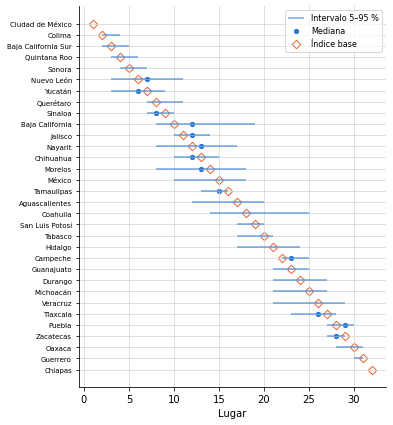

In [8]:
rng = np.random.default_rng(2026)
B = 10_000
normas = [norm_z, norm_minmax, norm_rango]
rangos = np.empty((B, len(D)))
for b in range(B):
    N = normas[rng.integers(3)](D)
    wb = rng.dirichlet(np.full(4, 5.0))
    I = lineal(N, wb) if rng.random() < 0.5 else geometrica(N, wb)
    rangos[b] = I.rank(ascending=False).values
mc = pd.DataFrame({"base": base.rank(ascending=False), "mediana": np.median(rangos, 0),
                   "p05": np.percentile(rangos, 5, 0), "p95": np.percentile(rangos, 95, 0)},
                  index=D.index).sort_values("base")
print("Cambio absoluto medio de lugar:", np.abs(rangos - mc.base.reindex(D.index).values).mean().round(2))

fig, ax = plt.subplots(figsize=(5.5, 7))
y = np.arange(len(mc))[::-1]
ax.hlines(y, mc.p05, mc.p95, color=AZUL, lw=2, alpha=0.5, label="Intervalo 5–95 %")
ax.scatter(mc.mediana, y, color=AZUL, s=18, label="Mediana")
ax.scatter(mc.base, y, marker="D", facecolor="white", edgecolor=NARANJA, label="Índice base")
ax.set_yticks(y); ax.set_yticklabels(mc.index, fontsize=7); ax.set_xlabel("Lugar"); ax.legend(fontsize=8)
plt.show()

### Lea la salida

1. En promedio, una entidad cambia `____` lugares entre réplicas.
2. Las entidades que conservan su lugar en todo el intervalo del 5 al 95 % son `____` y `____`.
3. El intervalo de Nuevo León va del lugar `____` al `____`. ¿Tiene sentido afirmar que NL (lugar 6) "está mejor" que Yucatán (lugar 7)? `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 1.23 lugares.
2. La Ciudad de México (1–1) y Chiapas (32–32).
3. Del 3 al 11. No: los intervalos se traslapan mucho (Yucatán va del 3 al 9). Las diferencias de uno o dos lugares no son robustas, y por eso se reportan los intervalos junto con el lugar.

</details>

## 6. Beneficio de la duda

$I_i = \max_{\mathbf{w}\ge 0} \mathbf{w}'\mathbf{y}_i$ sujeto a $\mathbf{w}'\mathbf{y}_k \le 1$ para toda $k$.

In [9]:
Ypos = M100.values
bod = pd.Series([-linprog(-Ypos[i], A_ub=Ypos, b_ub=np.ones(len(Ypos)), bounds=[(0, None)] * 4,
                          method="highs").fun for i in range(len(Ypos))], index=D.index)
print("Spearman con el índice base:", round(stats.spearmanr(bod, base)[0], 3))
bod.sort_values(ascending=False).round(3)

Spearman con el índice base: 0.919


entidad
Ciudad de México       1.000
Nuevo León             0.914
Baja California Sur    0.865
Baja California        0.822
Querétaro              0.787
Colima                 0.753
Quintana Roo           0.748
Sonora                 0.737
Chihuahua              0.736
Jalisco                0.710
Coahuila               0.704
Aguascalientes         0.695
Sinaloa                0.627
México                 0.624
Tamaulipas             0.615
Yucatán                0.614
Nayarit                0.592
San Luis Potosí        0.535
Morelos                0.529
Durango                0.517
Veracruz               0.507
Hidalgo                0.502
Guanajuato             0.498
Michoacán              0.490
Tlaxcala               0.487
Tabasco                0.463
Campeche               0.437
Puebla                 0.406
Zacatecas              0.358
Oaxaca                 0.323
Guerrero               0.230
Chiapas                0.021
dtype: float64

### Lea la salida

1. Con beneficio de la duda, NL obtiene `____` y queda en el lugar `____`, contra el `____` del índice base.
2. Esto ocurre porque el beneficio de la duda `____`.
3. Chiapas obtiene `____`, lo que significa que `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. 0.914, segundo lugar, contra el sexto del índice base.
2. Elige para cada entidad los pesos que más la favorecen. NL tiene el segundo ingreso más alto y puede poner casi todo el peso ahí, lo que oculta su valor bajo en perceptores.
3. 0.021: ni con los pesos más favorables sale bien, porque está abajo en los cuatro indicadores.

</details>

## 7. Validación con la ley de Engel

In [10]:
with zipfile.ZipFile("../../03 Factor Analysis/03 ENIGH/enigh2024_ns_concentradohogar_csv.zip") as z:
    hog = pd.read_csv(z.open("concentradohogar.csv"), low_memory=False, dtype={"ubica_geo": str},
                      usecols=["ubica_geo", "factor", "alimentos", "gasto_mon"])
g = hog.ubica_geo.str.zfill(5).str[:2].astype(int)
ali = (hog.alimentos * hog.factor).groupby(g).sum() / (hog.gasto_mon * hog.factor).groupby(g).sum()
ali.index = D.index
print(f"Proporción del gasto en alimentos: de {ali.min():.1%} ({ali.idxmin()}) a {ali.max():.1%} ({ali.idxmax()})")
print("Correlación con el índice:", np.corrcoef(base, ali)[0, 1].round(3), "| Spearman:", round(stats.spearmanr(base, ali)[0], 3))

Proporción del gasto en alimentos: de 31.8% (Coahuila) a 46.5% (Chiapas)
Correlación con el índice: -0.486 | Spearman: -0.452


### Lea la salida

1. La correlación del índice con la proporción del gasto en alimentos es `____`; su signo es el `____` (esperado / inesperado) por la ley de Engel.
2. Es una validación "externa" porque `____`.
3. La correlación es moderada; una razón posible es `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

1. −0.486: el signo esperado, porque las entidades con mejores condiciones dedican una proporción menor de su gasto a alimentos.
2. La proporción del gasto en alimentos no se usó para construir el índice.
3. Por ejemplo, diferencias regionales de precios y de patrones de consumo que el índice no mide.

</details>

## 8. El índice resultante

In [11]:
final = pd.DataFrame({"índice": base.round(3), "lugar": mc.base.reindex(D.index).astype(int),
                      "intervalo 5-95": mc.p05.reindex(D.index).astype(int).astype(str) + "–" + mc.p95.reindex(D.index).astype(int).astype(str)})
final.sort_values("lugar")

,índice,lugar,intervalo 5-95
entidad,,,
Ciudad de México,2.810,1,1–1
Colima,1.017,2,2–4
Baja California Sur,0.822,3,2–5
Quintana Roo,0.752,4,3–6
Sonora,0.724,5,4–7
Nuevo León,0.665,6,3–11
Yucatán,0.641,7,3–9
Querétaro,0.522,8,7–11
Sinaloa,0.455,9,7–10


## 9. Autoevaluación

Tres reactivos con el formato del quiz y del examen: elija una opción y complete la justificación. No cuentan para la calificación.

**Reactivo 1.** Se agrega a la base una entidad ficticia con `ing_pc` = 11.5, mayor que el de la Ciudad de México (10.78). Con normalización mín–máx, ¿qué ocurre con el ingreso normalizado de las 32 entidades?

- (a) No cambia, porque cada entidad conserva su ingreso y la normalización sólo depende de los datos de la propia entidad.
- (b) Se comprime hacia 0, porque el máximo de la escala ya no es la CDMX, pero el orden de las 32 en ese indicador no cambia.
- (c) Se invierte el orden de las entidades en ese indicador, porque la nueva entidad cambia el máximo entre el que se divide.
- (d) Todas las entidades suben, porque al aumentar el rango de la variable aumentan también todos sus valores normalizados.

*Justificación:* mín–máx calcula $(x - \min)/($`____` $-$ `____`$)$. Al crecer el máximo, el denominador `____` y cada valor `____`. Como la transformación es `____` (creciente / decreciente), el orden en el indicador `____`. Aun así, el índice `____` (puede / no puede) cambiar, porque `____`.

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** El denominador $\max - \min$ crece y cada valor normalizado baja; la transformación es creciente, así que el orden en el ingreso se conserva. Pero el índice sí puede cambiar: el ingreso queda con valores más bajos y menos dispersos, y pesa menos frente a los otros tres indicadores. Es la misma sensibilidad a atípicos que se vio con la CDMX.

</details>

**Reactivo 2.** Chiapas tiene $z = -2.24$ en `menores_sh`, ya con la polaridad aplicada. ¿Qué significa?

- (a) Su proporción de menores está 2.24 desviaciones estándar por debajo del promedio, lo que indica condiciones mejores que el promedio.
- (b) Su proporción de menores está 2.24 desviaciones estándar por encima del promedio, lo que indica condiciones peores que el promedio.
- (c) Hay un error: con la polaridad aplicada, un valor $z$ negativo es imposible, porque la inversión vuelve positivos todos los valores.
- (d) Su proporción de menores es 2.24 % menor que el promedio nacional, porque $z$ expresa una diferencia porcentual respecto a la media.

*Justificación:* sin polaridad, $z =$ `____`; la polaridad multiplica por `____`. Una proporción de menores alta significa `____`, y en el índice `____` (suma / resta).

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** Sin polaridad, $z = +2.24$ (Chiapas tiene la proporción de menores más alta, 0.221, contra un promedio de 0.176). La polaridad multiplica por $-1$: una proporción alta de menores indica peores condiciones y resta en el índice. La inversión cambia el signo, no lo vuelve positivo (c), y $z$ se mide en desviaciones estándar, no en porcentaje (d).

</details>

**Reactivo 3.** Con beneficio de la duda, Nuevo León sube del lugar 6 al 2. ¿Por qué?

- (a) Porque el beneficio de la duda usa los pesos del análisis factorial, que dan más peso al ingreso, donde destaca NL.
- (b) Porque deja que cada entidad elija los pesos que más la favorecen, y NL puede cargar casi todo en su ingreso, el segundo más alto.
- (c) Porque el beneficio de la duda castiga los perfiles desbalanceados, como la agregación geométrica, y el de NL es muy parejo.
- (d) Porque hay un error en la programación lineal: con los mismos datos, ningún método razonable mueve a una entidad cuatro lugares.

*Justificación:* el beneficio de la duda maximiza, para cada entidad, `____` sujeto a `____`. NL está en el lugar `____` en ingreso y por debajo del promedio en `____`. Por eso este método favorece los perfiles `____` (especializados / parejos).

<details><summary><b>Respuesta</b> (ábrala después de completar)</summary>

**(b).** Para cada entidad maximiza $\mathbf{w}'\mathbf{y}_i$ sujeto a que ninguna entidad supere 1 con esos mismos pesos. NL es segundo en ingreso y está por debajo del promedio en perceptores: el método favorece los perfiles especializados, lo contrario de la agregación geométrica (c). No usa pesos factoriales (a), y el cambio no es un error (d): refleja que el lugar depende de los pesos.

</details>

## Ejercicio para el alumno

Repita el análisis Monte Carlo agregando como fuente de incertidumbre la inclusión o exclusión de la proporción de perceptores. ¿Qué entidades se vuelven más inciertas?